# Campaign Revenue Intelligence — Exploratory Data Analysis

## 1. Business Objective

Analyze campaign-level advertising performance across clients and marketing channels.

The objectives are to:
- Understand advertising spend and attributed revenue.
- Evaluate the marketing conversion funnel.
- Compare channel and campaign performance.
- Investigate revenue concentration and monthly trends.
- Examine feature relationships, zero-heavy targets, and outliers.
- Prepare leakage-safe features for campaign revenue forecasting.

**Dataset:** `data/processed_candidate/campaign_daily.parquet`

**Important:** This is a synthetic dataset created for portfolio and modeling purposes. Findings demonstrate analytical methods and are not claims about real advertising performance.


## 2. Imports and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

plt.rcParams['figure.figsize'] = (12, 5)

PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == 'notebooks':
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / 'data' / 'processed_candidate'
DATA_PATH = DATA_DIR / 'campaign_daily.parquet'

print('Project directory:', PROJECT_DIR)
print('Data directory:', DATA_DIR)
print('Data directory exists:', DATA_DIR.exists())

assert DATA_PATH.exists(), f'Dataset not found: {DATA_PATH}'

df = pd.read_parquet(DATA_PATH)

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['campaign_id', 'date']).reset_index(drop=True)

print('Dataset loaded successfully.')
print('Shape:', df.shape)


Project directory: /Users/nithiii/Downloads/data-science-ai-portfolio/02-deep-learning/agency-revenue-intelligence
Data directory: /Users/nithiii/Downloads/data-science-ai-portfolio/02-deep-learning/agency-revenue-intelligence/data/processed_candidate
Data directory exists: True
Dataset loaded successfully.
Shape: (20051, 11)


## 3. Dataset Overview

In [2]:
display(df.head())

print('\nDataset shape:', df.shape)
print('\nColumns:')
print(df.columns.tolist())

print('\nData types:')
print(df.dtypes)

print('\nDate range:', df['date'].min(), 'to', df['date'].max())
print('Unique campaigns:', df['campaign_id'].nunique())
print('Unique clients:', df['client_id'].nunique())
print('Channels:', sorted(df['channel'].unique()))
print('Synthetic records only:', df['synthetic_data'].all())


,date,campaign_id,client_id,channel,spend_inr,impressions,clicks,leads,conversions,attributed_campaign_revenue,synthetic_data
0,2025-08-05,CAM0001,CL0015,affiliate,"6,054.73",11840,263,17,2,"7,235.40",True
1,2025-08-06,CAM0001,CL0015,affiliate,"7,610.58",9004,200,12,1,"2,971.50",True
2,2025-08-07,CAM0001,CL0015,affiliate,"6,484.86",7304,196,9,1,"2,328.18",True
3,2025-08-08,CAM0001,CL0015,affiliate,"6,030.19",7402,174,8,1,"3,185.49",True
4,2025-08-09,CAM0001,CL0015,affiliate,"5,697.82",7411,172,7,2,"7,190.38",True



Dataset shape: (20051, 11)

Columns:
['date', 'campaign_id', 'client_id', 'channel', 'spend_inr', 'impressions', 'clicks', 'leads', 'conversions', 'attributed_campaign_revenue', 'synthetic_data']

Data types:
date                           datetime64[ns]
campaign_id                            object
client_id                              object
channel                                object
spend_inr                             float64
impressions                             int64
clicks                                  int64
leads                                   int64
conversions                             int64
attributed_campaign_revenue           float64
synthetic_data                           bool
dtype: object

Date range: 2024-11-06 00:00:00 to 2026-10-31 00:00:00
Unique campaigns: 100
Unique clients: 41
Channels: ['affiliate', 'display', 'email', 'search', 'social', 'video']
Synthetic records only: True


## 4. Data Quality and Validation

In [3]:
print('Missing values:')
display(df.isnull().sum().to_frame('missing_count'))

print('Fully duplicated rows:', df.duplicated().sum())
print(
    'Duplicate campaign-date combinations:',
    df.duplicated(['campaign_id', 'date']).sum()
)

numeric_cols = [
    'spend_inr', 'impressions', 'clicks',
    'leads', 'conversions', 'attributed_campaign_revenue'
]

print('\nNegative numeric values:')
display((df[numeric_cols] < 0).sum().to_frame('negative_count'))

funnel_checks = pd.Series({
    'Clicks greater than impressions': (df['clicks'] > df['impressions']).sum(),
    'Leads greater than clicks': (df['leads'] > df['clicks']).sum(),
    'Conversions greater than leads': (df['conversions'] > df['leads']).sum()
}, name='invalid_records')

display(funnel_checks.to_frame())

assert df.isnull().sum().sum() == 0, 'Missing values detected.'
assert df.duplicated().sum() == 0, 'Duplicate rows detected.'
assert df.duplicated(['campaign_id', 'date']).sum() == 0
assert (df[numeric_cols] < 0).sum().sum() == 0
assert funnel_checks.sum() == 0, 'Funnel consistency issue detected.'

print('All initial data quality assertions passed.')


Missing values:


,missing_count
date,0
campaign_id,0
client_id,0
channel,0
spend_inr,0
impressions,0
clicks,0
leads,0
conversions,0
attributed_campaign_revenue,0


Fully duplicated rows: 0
Duplicate campaign-date combinations: 0

Negative numeric values:


,negative_count
spend_inr,0
impressions,0
clicks,0
leads,0
conversions,0
attributed_campaign_revenue,0


,invalid_records
Clicks greater than impressions,0
Leads greater than clicks,0
Conversions greater than leads,0


All initial data quality assertions passed.


## 5. Descriptive Statistics

In [4]:
display(df[numeric_cols].describe().T)

print('\nZero-activity observations:')
zero_summary = pd.DataFrame({
    'zero_records': (df[['clicks', 'leads', 'conversions',
                         'attributed_campaign_revenue']] == 0).sum()
})
zero_summary['percentage'] = zero_summary['zero_records'] / len(df) * 100
display(zero_summary.round(2))


,count,mean,std,min,25%,50%,75%,max
spend_inr,"20,051.00","6,754.30","3,119.02",538.16,"4,424.72","6,564.60","9,082.56","16,395.08"
impressions,"20,051.00","19,691.99","20,821.17",139.00,"6,877.00","12,750.00","25,023.50","226,889.00"
clicks,"20,051.00",316.20,235.16,7.00,156.00,253.00,404.00,"1,911.00"
leads,"20,051.00",14.74,17.25,0.00,4.00,9.00,19.00,203.00
conversions,"20,051.00",1.64,2.87,0.00,0.00,1.00,2.00,41.00
attributed_campaign_revenue,"20,051.00","6,490.82","13,034.10",0.00,0.00,"2,530.57","7,312.44","253,358.30"



Zero-activity observations:


,zero_records,percentage
clicks,0,0.00
leads,638,3.18
conversions,9246,46.11
attributed_campaign_revenue,9246,46.11


## 6. Marketing Funnel and Overall KPIs

Metrics are calculated from aggregated totals, not by averaging daily percentages.

- CTR = Clicks / Impressions
- Click-to-Lead Rate = Leads / Clicks
- Lead-to-Conversion Rate = Conversions / Leads
- Click-to-Conversion Rate = Conversions / Clicks
- CPC = Spend / Clicks
- CPL = Spend / Leads
- CPA = Spend / Conversions
- ROAS = Attributed Revenue / Spend


In [5]:
totals = df[numeric_cols].sum()

def safe_divide(numerator, denominator):
    return numerator / denominator if denominator != 0 else np.nan

overall_kpis = pd.Series({
    'Total Spend (INR)': totals['spend_inr'],
    'Total Attributed Revenue (INR)': totals['attributed_campaign_revenue'],
    'Total Impressions': totals['impressions'],
    'Total Clicks': totals['clicks'],
    'Total Leads': totals['leads'],
    'Total Conversions': totals['conversions'],
    'CTR (%)': safe_divide(totals['clicks'], totals['impressions']) * 100,
    'Click-to-Lead Rate (%)': safe_divide(totals['leads'], totals['clicks']) * 100,
    'Lead-to-Conversion Rate (%)': safe_divide(totals['conversions'], totals['leads']) * 100,
    'Click-to-Conversion Rate (%)': safe_divide(totals['conversions'], totals['clicks']) * 100,
    'CPC (INR)': safe_divide(totals['spend_inr'], totals['clicks']),
    'CPL (INR)': safe_divide(totals['spend_inr'], totals['leads']),
    'CPA (INR)': safe_divide(totals['spend_inr'], totals['conversions']),
    'ROAS': safe_divide(totals['attributed_campaign_revenue'], totals['spend_inr'])
}, name='value')

display(overall_kpis.to_frame().round(2))


,value
Total Spend (INR),"135,430,427.90"
Total Attributed Revenue (INR),"130,147,356.13"
Total Impressions,"394,844,033.00"
Total Clicks,"6,340,076.00"
Total Leads,"295,591.00"
Total Conversions,"32,797.00"
CTR (%),1.61
Click-to-Lead Rate (%),4.66
Lead-to-Conversion Rate (%),11.10
Click-to-Conversion Rate (%),0.52


## 7. Channel-Level Performance

In [6]:
channel = df.groupby('channel').agg(
    campaign_days=('campaign_id', 'size'),
    campaigns=('campaign_id', 'nunique'),
    clients=('client_id', 'nunique'),
    spend=('spend_inr', 'sum'),
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    leads=('leads', 'sum'),
    conversions=('conversions', 'sum'),
    revenue=('attributed_campaign_revenue', 'sum')
)

channel['CTR_pct'] = channel['clicks'] / channel['impressions'] * 100
channel['click_to_lead_pct'] = channel['leads'] / channel['clicks'] * 100
channel['conversion_rate_pct'] = channel['conversions'] / channel['clicks'] * 100
channel['ROAS'] = channel['revenue'] / channel['spend']
channel['CPC'] = channel['spend'] / channel['clicks']
channel['CPA'] = channel['spend'] / channel['conversions'].replace(0, np.nan)

channel = channel.sort_values('revenue', ascending=False)

display(channel.round(2))


,campaign_days,campaigns,clients,spend,impressions,clicks,leads,conversions,revenue,CTR_pct,click_to_lead_pct,conversion_rate_pct,ROAS,CPC,CPA
channel,,,,,,,,,,,,,,,
email,2518,14,12,"16,361,122.65",17228752,772052,77151,11073,"48,314,271.00",4.48,9.99,1.43,2.95,21.19,"1,477.57"
search,3270,17,15,"22,380,345.01",29893098,1040361,83329,10434,"46,116,270.79",3.48,8.01,1.00,2.06,21.51,"2,144.94"
affiliate,3227,15,12,"22,460,125.11",41814828,1040868,57455,5917,"19,649,617.51",2.49,5.52,0.57,0.87,21.58,"3,795.86"
social,3592,18,14,"20,796,039.04",54733046,971884,35609,3002,"8,514,401.11",1.78,3.66,0.31,0.41,21.40,"6,927.39"
video,3171,16,12,"23,222,344.48",91171010,1086432,21576,1368,"4,568,358.03",1.19,1.99,0.13,0.20,21.37,"16,975.40"
display,4273,20,17,"30,210,451.61",160003299,1428479,20471,1003,"2,984,437.69",0.89,1.43,0.07,0.10,21.15,"30,120.09"


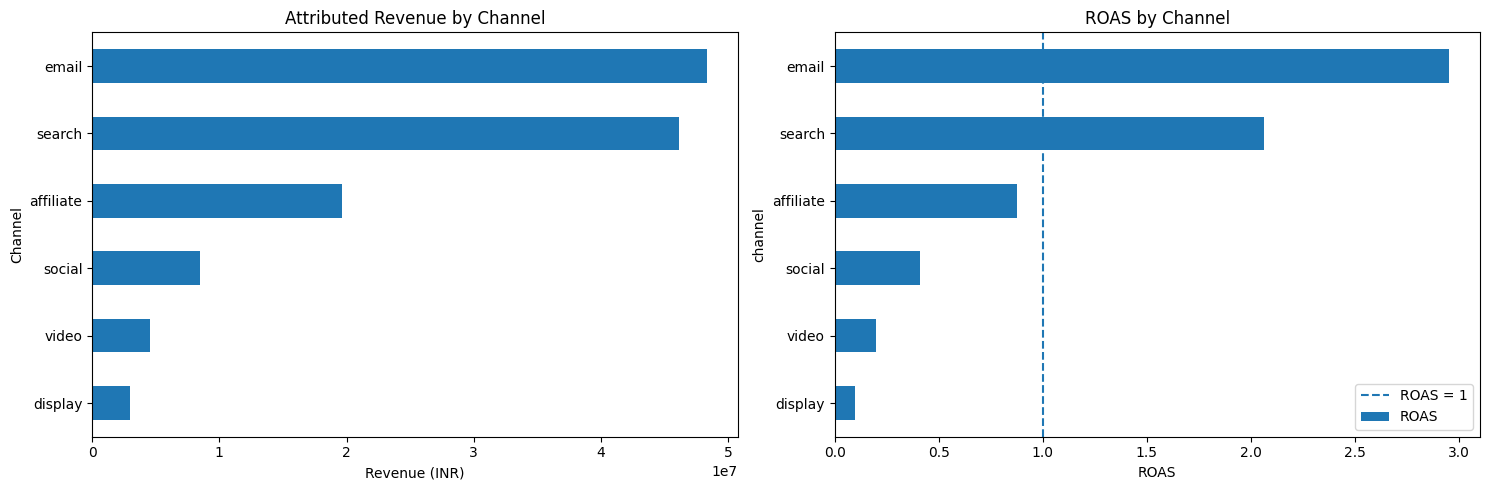

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

channel['revenue'].sort_values().plot(
    kind='barh', ax=axes[0], title='Attributed Revenue by Channel'
)
axes[0].set_xlabel('Revenue (INR)')
axes[0].set_ylabel('Channel')

channel['ROAS'].sort_values().plot(
    kind='barh', ax=axes[1], title='ROAS by Channel'
)
axes[1].axvline(1, linestyle='--', label='ROAS = 1')
axes[1].set_xlabel('ROAS')
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Campaign-Level Performance and Revenue Concentration

In [8]:
campaign = df.groupby(['campaign_id', 'client_id', 'channel']).agg(
    active_days=('date', 'nunique'),
    spend=('spend_inr', 'sum'),
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    leads=('leads', 'sum'),
    conversions=('conversions', 'sum'),
    revenue=('attributed_campaign_revenue', 'sum')
).reset_index()

campaign['ROAS'] = campaign['revenue'] / campaign['spend']
campaign['CTR_pct'] = campaign['clicks'] / campaign['impressions'] * 100
campaign['conversion_rate_pct'] = campaign['conversions'] / campaign['clicks'] * 100
campaign['CPA'] = campaign['spend'] / campaign['conversions'].replace(0, np.nan)

print('Top 10 campaigns by revenue')
display(campaign.nlargest(10, 'revenue').round(2))

print('Top 10 campaigns by ROAS')
display(campaign.nlargest(10, 'ROAS').round(2))

print('Bottom 10 campaigns by ROAS')
display(campaign.nsmallest(10, 'ROAS').round(2))

print('Campaign-level performance distribution')
display(campaign[['spend', 'revenue', 'ROAS', 'CTR_pct',
                  'conversion_rate_pct', 'CPA']].describe().round(2))


Top 10 campaigns by revenue


,campaign_id,client_id,channel,active_days,spend,impressions,clicks,leads,conversions,revenue,ROAS,CTR_pct,conversion_rate_pct,CPA
6,CAM0007,CL0020,email,289,"3,318,006.02",3435978,155871,14889,2042,"9,590,403.87",2.89,4.54,1.31,"1,624.88"
85,CAM0086,CL0013,search,145,"1,606,252.29",2222554,75956,9581,1885,"8,443,654.56",5.26,3.42,2.48,852.12
96,CAM0097,CL0005,email,254,"1,097,626.75",1139786,50584,6561,1205,"7,306,499.35",6.66,4.44,2.38,910.89
23,CAM0024,CL0041,email,199,"1,806,621.01",1881889,83695,10197,1719,"7,280,995.22",4.03,4.45,2.05,"1,050.97"
34,CAM0035,CL0036,email,127,"1,427,040.02",1410603,64752,7396,1225,"7,121,545.03",4.99,4.59,1.89,"1,164.93"
39,CAM0040,CL0010,search,346,"2,492,642.05",3299725,115096,9113,1106,"4,880,955.48",1.96,3.49,0.96,"2,253.75"
20,CAM0021,CL0021,search,273,"1,764,641.01",2366645,81118,6675,819,"4,550,636.68",2.58,3.43,1.01,"2,154.63"
21,CAM0022,CL0003,search,217,"2,044,460.71",2794735,98462,7760,928,"4,366,235.56",2.14,3.52,0.94,"2,203.08"
44,CAM0045,CL0033,email,201,"1,198,989.14",1340993,60167,6258,886,"3,900,467.73",3.25,4.49,1.47,"1,353.26"
43,CAM0044,CL0009,search,222,"1,820,345.01",2461862,85812,7063,881,"3,595,969.19",1.98,3.49,1.03,"2,066.23"


Top 10 campaigns by ROAS


,campaign_id,client_id,channel,active_days,spend,impressions,clicks,leads,conversions,revenue,ROAS,CTR_pct,conversion_rate_pct,CPA
96,CAM0097,CL0005,email,254,"1,097,626.75",1139786,50584,6561,1205,"7,306,499.35",6.66,4.44,2.38,910.89
85,CAM0086,CL0013,search,145,"1,606,252.29",2222554,75956,9581,1885,"8,443,654.56",5.26,3.42,2.48,852.12
34,CAM0035,CL0036,email,127,"1,427,040.02",1410603,64752,7396,1225,"7,121,545.03",4.99,4.59,1.89,"1,164.93"
50,CAM0051,CL0012,email,122,"169,839.95",176813,7780,1080,217,"799,454.27",4.71,4.40,2.79,782.67
23,CAM0024,CL0041,email,199,"1,806,621.01",1881889,83695,10197,1719,"7,280,995.22",4.03,4.45,2.05,"1,050.97"
44,CAM0045,CL0033,email,201,"1,198,989.14",1340993,60167,6258,886,"3,900,467.73",3.25,4.49,1.47,"1,353.26"
55,CAM0056,CL0029,email,330,"265,888.71",268043,11875,1141,169,"806,492.75",3.03,4.43,1.42,"1,573.31"
6,CAM0007,CL0020,email,289,"3,318,006.02",3435978,155871,14889,2042,"9,590,403.87",2.89,4.54,1.31,"1,624.88"
37,CAM0038,CL0033,email,121,"1,190,641.99",1231483,55028,6486,1036,"3,306,047.94",2.78,4.47,1.88,"1,149.27"
90,CAM0091,CL0029,search,98,"1,020,343.17",1306784,46813,4344,584,"2,716,378.73",2.66,3.58,1.25,"1,747.16"


Bottom 10 campaigns by ROAS


,campaign_id,client_id,channel,active_days,spend,impressions,clicks,leads,conversions,revenue,ROAS,CTR_pct,conversion_rate_pct,CPA
35,CAM0036,CL0037,display,139,"792,468.61",4062951,36289,444,13,"30,711.63",0.04,0.89,0.04,"60,959.12"
81,CAM0082,CL0007,display,92,"497,960.24",2547694,23074,247,6,"19,987.52",0.04,0.91,0.03,"82,993.37"
78,CAM0079,CL0010,display,170,"1,622,419.63",7964296,71073,786,34,"82,044.07",0.05,0.89,0.05,"47,718.22"
42,CAM0043,CL0049,display,117,"217,676.92",1175571,10489,150,4,"13,087.86",0.06,0.89,0.04,"54,419.23"
36,CAM0037,CL0001,display,248,"425,474.53",2217780,19736,217,10,"25,697.25",0.06,0.89,0.05,"42,547.45"
64,CAM0065,CL0040,display,286,"3,229,984.18",17852448,159221,2165,92,"209,400.24",0.06,0.89,0.06,"35,108.52"
95,CAM0096,CL0016,display,281,"1,467,856.31",7750441,68669,755,27,"98,682.47",0.07,0.89,0.04,"54,365.05"
71,CAM0072,CL0038,display,264,"2,844,111.56",15150299,135105,1444,52,"200,092.92",0.07,0.89,0.04,"54,694.45"
17,CAM0018,CL0039,display,341,"3,583,289.15",19670895,175914,2906,137,"350,654.08",0.10,0.89,0.08,"26,155.40"
1,CAM0002,CL0038,display,209,"736,393.89",3859154,34401,465,23,"73,075.25",0.10,0.89,0.07,"32,017.13"


Campaign-level performance distribution


,spend,revenue,ROAS,CTR_pct,conversion_rate_pct,CPA
count,100.00,100.00,100.00,100.00,100.00,100.00
mean,"1,354,304.28","1,301,473.56",1.01,2.28,0.55,"13,117.94"
std,"755,275.62","1,894,956.28",1.27,1.25,0.58,"15,345.94"
min,"72,735.06","9,615.46",0.04,0.88,0.03,782.67
25%,"800,648.66","198,893.30",0.16,1.19,0.11,"2,565.54"
50%,"1,212,448.12","581,545.74",0.43,1.79,0.32,"6,660.60"
75%,"1,810,052.01","1,491,746.09",1.49,3.47,0.85,"19,108.50"
max,"3,583,289.15","9,590,403.87",6.66,4.59,2.79,"82,993.37"


In [9]:
campaign_ranked = campaign.sort_values('revenue', ascending=False).copy()

total_revenue = campaign_ranked['revenue'].sum()
campaign_ranked['revenue_share_pct'] = (
    campaign_ranked['revenue'] / total_revenue * 100
)
campaign_ranked['cumulative_revenue_share_pct'] = (
    campaign_ranked['revenue_share_pct'].cumsum()
)

concentration = pd.Series({
    f'Top {n} campaign revenue share (%)':
        campaign_ranked.head(n)['revenue'].sum() / total_revenue * 100
    for n in [5, 10, 20]
})

display(concentration.to_frame('percentage').round(2))
print('Campaigns with ROAS >= 1:', (campaign['ROAS'] >= 1).sum())
print('Campaigns with ROAS < 1:', (campaign['ROAS'] < 1).sum())

display(campaign_ranked.head(15).round(2))


,percentage
Top 5 campaign revenue share (%),30.54
Top 10 campaign revenue share (%),46.90
Top 20 campaign revenue share (%),66.97


Campaigns with ROAS >= 1: 33
Campaigns with ROAS < 1: 67


,campaign_id,client_id,channel,active_days,spend,impressions,clicks,leads,conversions,revenue,ROAS,CTR_pct,conversion_rate_pct,CPA,revenue_share_pct,cumulative_revenue_share_pct
6,CAM0007,CL0020,email,289,"3,318,006.02",3435978,155871,14889,2042,"9,590,403.87",2.89,4.54,1.31,"1,624.88",7.37,7.37
85,CAM0086,CL0013,search,145,"1,606,252.29",2222554,75956,9581,1885,"8,443,654.56",5.26,3.42,2.48,852.12,6.49,13.86
96,CAM0097,CL0005,email,254,"1,097,626.75",1139786,50584,6561,1205,"7,306,499.35",6.66,4.44,2.38,910.89,5.61,19.47
23,CAM0024,CL0041,email,199,"1,806,621.01",1881889,83695,10197,1719,"7,280,995.22",4.03,4.45,2.05,"1,050.97",5.59,25.07
34,CAM0035,CL0036,email,127,"1,427,040.02",1410603,64752,7396,1225,"7,121,545.03",4.99,4.59,1.89,"1,164.93",5.47,30.54
39,CAM0040,CL0010,search,346,"2,492,642.05",3299725,115096,9113,1106,"4,880,955.48",1.96,3.49,0.96,"2,253.75",3.75,34.29
20,CAM0021,CL0021,search,273,"1,764,641.01",2366645,81118,6675,819,"4,550,636.68",2.58,3.43,1.01,"2,154.63",3.50,37.78
21,CAM0022,CL0003,search,217,"2,044,460.71",2794735,98462,7760,928,"4,366,235.56",2.14,3.52,0.94,"2,203.08",3.35,41.14
44,CAM0045,CL0033,email,201,"1,198,989.14",1340993,60167,6258,886,"3,900,467.73",3.25,4.49,1.47,"1,353.26",3.00,44.14
43,CAM0044,CL0009,search,222,"1,820,345.01",2461862,85812,7063,881,"3,595,969.19",1.98,3.49,1.03,"2,066.23",2.76,46.90


## 9. Monthly Revenue, Spend, and ROAS Trends

In [10]:
df['month'] = df['date'].dt.to_period('M')

monthly = df.groupby('month').agg(
    spend=('spend_inr', 'sum'),
    revenue=('attributed_campaign_revenue', 'sum'),
    conversions=('conversions', 'sum'),
    active_campaigns=('campaign_id', 'nunique'),
    active_clients=('client_id', 'nunique'),
    campaign_days=('campaign_id', 'size')
)

monthly['ROAS'] = monthly['revenue'] / monthly['spend']
monthly['revenue_per_active_campaign'] = (
    monthly['revenue'] / monthly['active_campaigns']
)

display(monthly.round(2))


,spend,revenue,conversions,active_campaigns,active_clients,campaign_days,ROAS,revenue_per_active_campaign
month,,,,,,,,
2024-11,"591,441.17","650,870.80",147,3,3,59,1.10,"216,956.93"
2024-12,"1,326,146.11","1,509,899.14",365,7,6,148,1.14,"215,699.88"
2025-01,"2,222,917.84","2,590,190.10",643,10,9,257,1.17,"259,019.01"
2025-02,"2,712,786.06","3,445,703.31",784,13,11,315,1.27,"265,054.10"
2025-03,"3,183,592.07","4,953,401.93",1037,13,11,383,1.56,"381,030.92"
2025-04,"3,663,488.20","4,855,479.74",1029,17,12,456,1.33,"285,616.46"
2025-05,"4,363,954.16","6,072,026.84",1280,20,15,560,1.39,"303,601.34"
2025-06,"4,079,352.70","4,432,716.38",1072,19,13,547,1.09,"233,300.86"
2025-07,"3,764,662.44","2,445,004.30",649,18,13,505,0.65,"135,833.57"


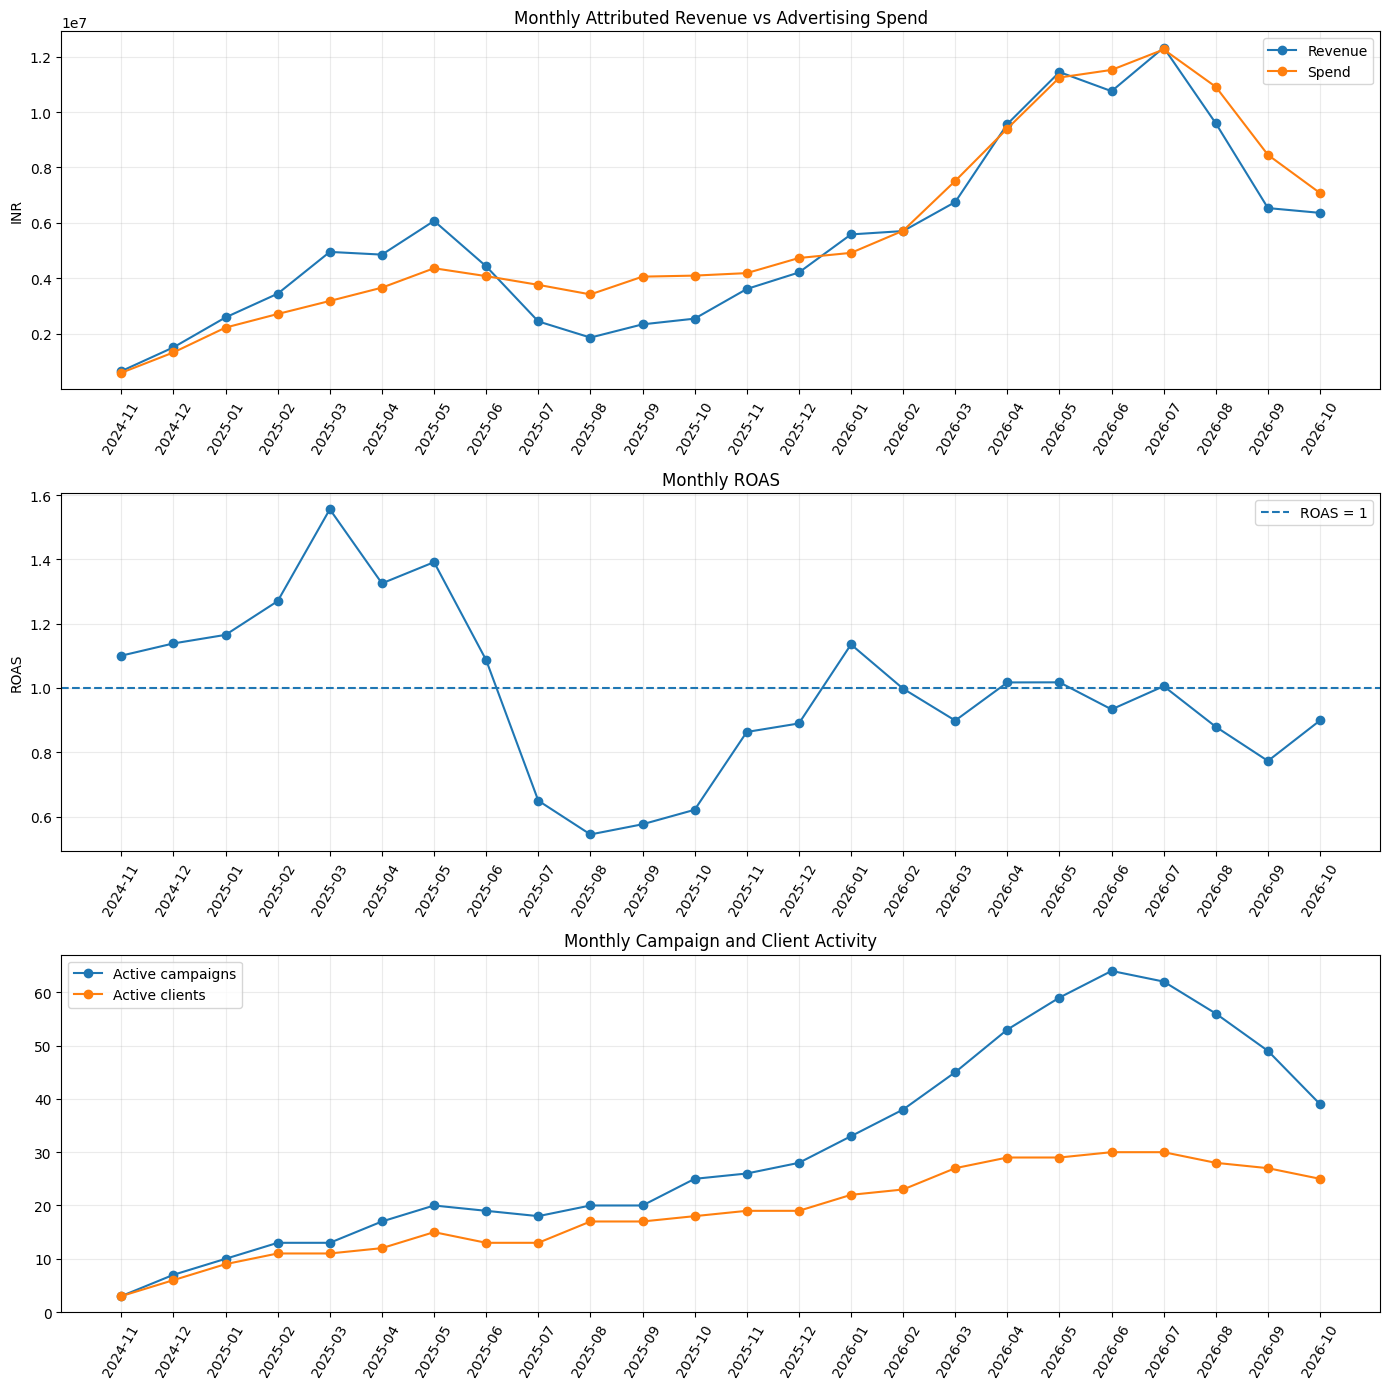

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

x = monthly.index.astype(str)

axes[0].plot(x, monthly['revenue'], marker='o', label='Revenue')
axes[0].plot(x, monthly['spend'], marker='o', label='Spend')
axes[0].set_title('Monthly Attributed Revenue vs Advertising Spend')
axes[0].set_ylabel('INR')
axes[0].legend()

axes[1].plot(x, monthly['ROAS'], marker='o')
axes[1].axhline(1, linestyle='--', label='ROAS = 1')
axes[1].set_title('Monthly ROAS')
axes[1].set_ylabel('ROAS')
axes[1].legend()

axes[2].plot(x, monthly['active_campaigns'], marker='o', label='Active campaigns')
axes[2].plot(x, monthly['active_clients'], marker='o', label='Active clients')
axes[2].set_title('Monthly Campaign and Client Activity')
axes[2].legend()

for ax in axes:
    ax.tick_params(axis='x', rotation=60)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 10. Correlation Analysis

,spend_inr,impressions,clicks,leads,conversions,attributed_campaign_revenue
spend_inr,1.00,0.48,0.62,0.38,0.28,0.25
impressions,0.48,1.00,0.75,0.04,-0.06,-0.08
clicks,0.62,0.75,1.00,0.62,0.43,0.38
leads,0.38,0.04,0.62,1.00,0.87,0.83
conversions,0.28,-0.06,0.43,0.87,1.00,0.96
attributed_campaign_revenue,0.25,-0.08,0.38,0.83,0.96,1.00


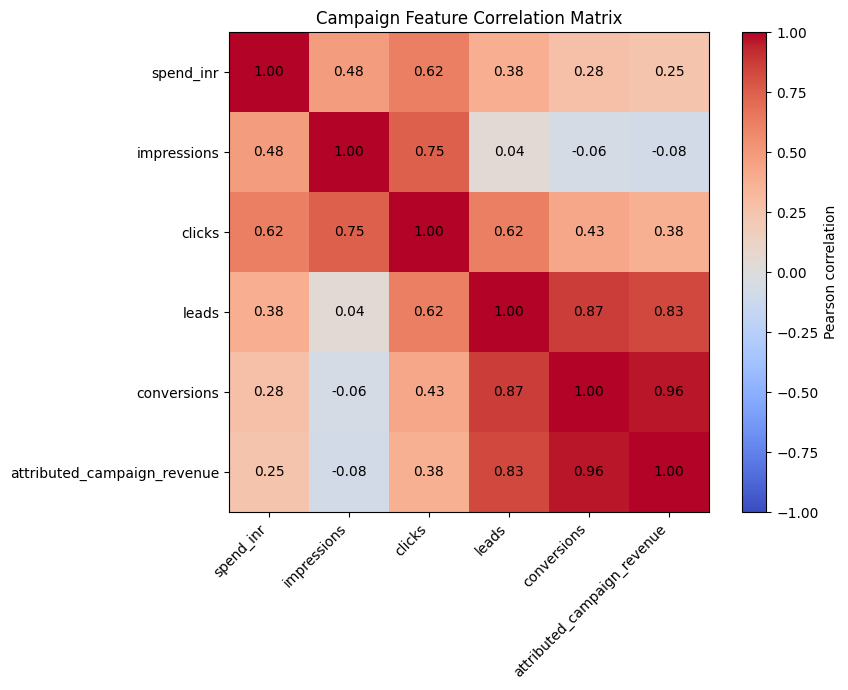

In [12]:
correlations = df[numeric_cols].corr()

display(correlations.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap='coolwarm')

ax.set_xticks(range(len(correlations.columns)))
ax.set_yticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=45, ha='right')
ax.set_yticklabels(correlations.columns)
ax.set_title('Campaign Feature Correlation Matrix')

for i in range(len(correlations)):
    for j in range(len(correlations)):
        ax.text(j, i, f'{correlations.iloc[i, j]:.2f}',
                ha='center', va='center')

fig.colorbar(image, ax=ax, label='Pearson correlation')
plt.tight_layout()
plt.show()


## 11. Outlier Analysis

The Interquartile Range (IQR) method identifies unusually high or low observations.

Outliers are not automatically errors. High campaign activity may be legitimate, so observations will be documented rather than removed without investigation.


In [13]:
outlier_rows = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_rows.append({
        'feature': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'lower_bound': lower,
        'upper_bound': upper,
        'outlier_count': count,
        'outlier_pct': count / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index('feature')
display(outlier_summary.round(2))


,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
feature,,,,,,,
spend_inr,"4,424.72","9,082.56","4,657.85","-2,562.06","16,069.34",4,0.02
impressions,"6,877.00","25,023.50","18,146.50","-20,342.75","52,243.25",1368,6.82
clicks,156.00,404.00,248.00,-216.00,776.00,1076,5.37
leads,4.00,19.00,15.00,-18.50,41.50,1379,6.88
conversions,0.00,2.00,2.00,-3.00,5.00,1435,7.16
attributed_campaign_revenue,0.00,"7,312.44","7,312.44","-10,968.66","18,281.10",1949,9.72


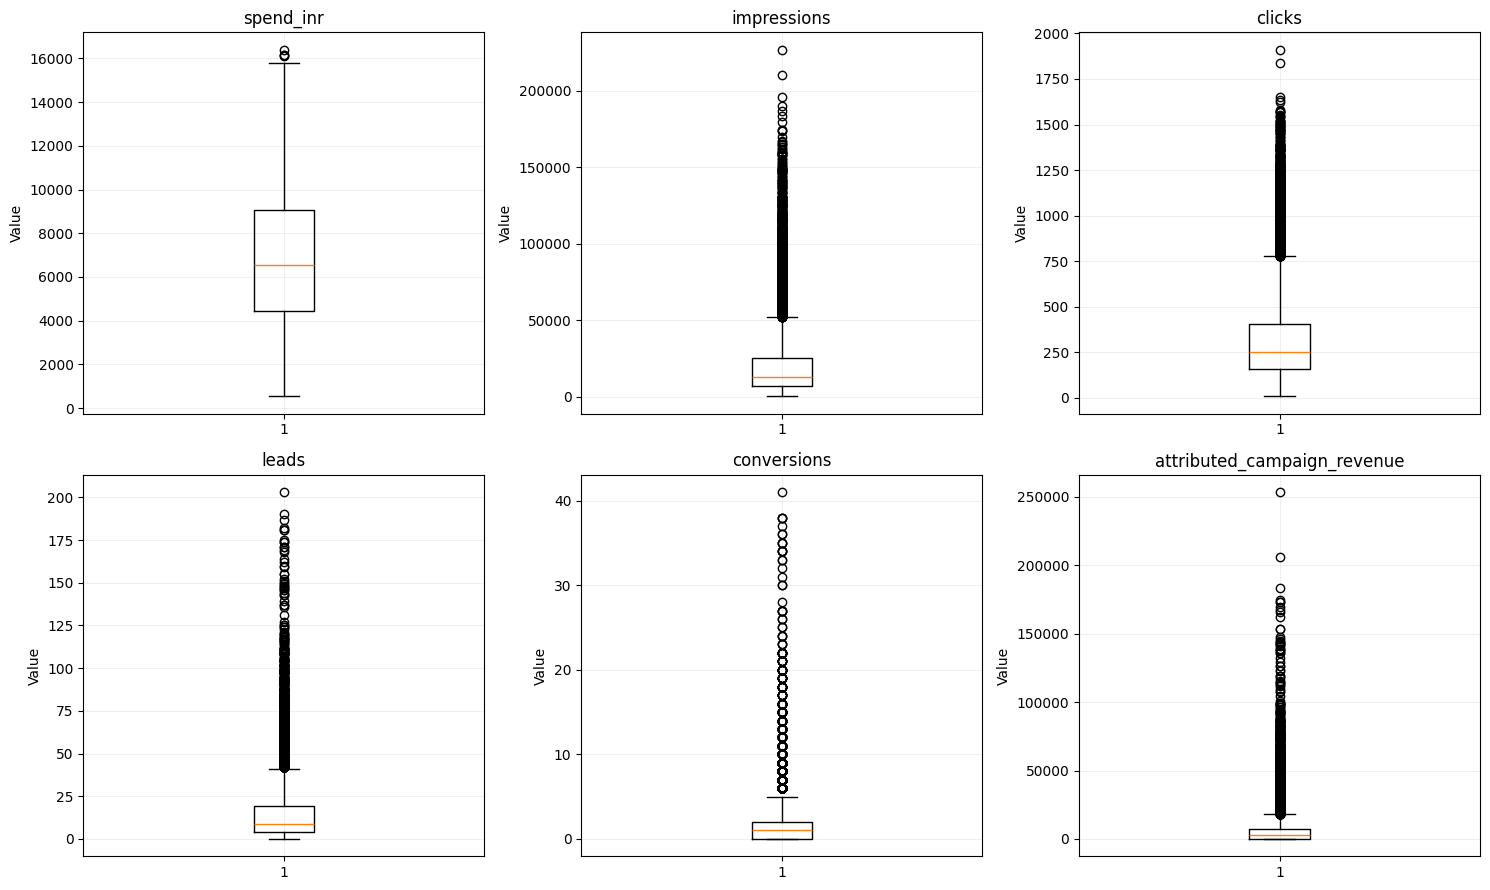

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flat, numeric_cols):
    ax.boxplot(df[col], vert=True)
    ax.set_title(col)
    ax.set_ylabel('Value')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


## 12. Campaign Activity and Continuity

In [15]:
duration = df.groupby('campaign_id').agg(
    first_active_date=('date', 'min'),
    last_active_date=('date', 'max'),
    active_days=('date', 'nunique')
)

duration['calendar_days'] = (
    duration['last_active_date'] - duration['first_active_date']
).dt.days + 1

duration['missing_days_in_span'] = (
    duration['calendar_days'] - duration['active_days']
)

display(duration[['active_days', 'calendar_days',
                  'missing_days_in_span']].describe().round(2))

print('Campaigns with gaps:',
      (duration['missing_days_in_span'] > 0).sum())

display(duration.sort_values('active_days').head(10))


,active_days,calendar_days,missing_days_in_span
count,100.00,100.00,100.00
mean,200.51,200.51,0.00
std,72.80,72.80,0.00
min,40.00,40.00,0.00
25%,138.00,138.00,0.00
50%,198.00,198.00,0.00
75%,247.25,247.25,0.00
max,359.00,359.00,0.00


Campaigns with gaps: 0


,first_active_date,last_active_date,active_days,calendar_days,missing_days_in_span
campaign_id,,,,,
CAM0020,2026-09-22,2026-10-31,40,40,0
CAM0089,2026-09-08,2026-10-31,54,54,0
CAM0078,2026-09-08,2026-10-31,54,54,0
CAM0082,2026-03-15,2026-06-14,92,92,0
CAM0081,2026-07-02,2026-10-03,94,94,0
CAM0091,2024-11-13,2025-02-18,98,98,0
CAM0005,2026-06-26,2026-10-06,103,103,0
CAM0062,2025-01-21,2025-05-09,109,109,0
CAM0066,2025-10-06,2026-01-26,113,113,0


## 13. Feature Engineering for Forecasting

Create historical features separately for each campaign.

Important leakage-prevention rule:

- Lag features use earlier observations.
- Rolling averages are shifted by one day before calculation.
- The current day's revenue is never included in its own historical rolling features.
- Calendar features are known in advance.

These features are exploratory preparation. The final forecasting pipeline must construct them within chronological train/validation/test boundaries.


In [16]:
features = df.sort_values(
    ['campaign_id', 'date']
).copy()

grouped = features.groupby('campaign_id', sort=False)

for lag in [1, 7, 14, 28]:
    features[f'revenue_lag_{lag}'] = grouped[
        'attributed_campaign_revenue'
    ].shift(lag)

for window in [7, 14, 28]:
    features[f'revenue_rolling_mean_{window}'] = (
        features.groupby('campaign_id')['attributed_campaign_revenue']
        .transform(lambda s: s.shift(1).rolling(window).mean())
    )

features['day_of_week'] = features['date'].dt.dayofweek
features['day_of_month'] = features['date'].dt.day
features['month_number'] = features['date'].dt.month
features['day_of_year'] = features['date'].dt.dayofyear
features['week_of_year'] = features['date'].dt.isocalendar().week.astype(int)

features['dow_sin'] = np.sin(2 * np.pi * features['day_of_week'] / 7)
features['dow_cos'] = np.cos(2 * np.pi * features['day_of_week'] / 7)

features['month_sin'] = np.sin(2 * np.pi * features['month_number'] / 12)
features['month_cos'] = np.cos(2 * np.pi * features['month_number'] / 12)

engineered_cols = [
    'revenue_lag_1', 'revenue_lag_7', 'revenue_lag_14',
    'revenue_lag_28', 'revenue_rolling_mean_7',
    'revenue_rolling_mean_14', 'revenue_rolling_mean_28',
    'day_of_week', 'month_number', 'dow_sin', 'dow_cos',
    'month_sin', 'month_cos'
]

display(features[['campaign_id', 'date',
                  'attributed_campaign_revenue'] + engineered_cols].head(35))

print('\nMissing values introduced by historical feature windows:')
display(features[engineered_cols].isnull().sum().to_frame('missing_count'))


,campaign_id,date,attributed_campaign_revenue,revenue_lag_1,revenue_lag_7,revenue_lag_14,revenue_lag_28,revenue_rolling_mean_7,revenue_rolling_mean_14,revenue_rolling_mean_28,day_of_week,month_number,dow_sin,dow_cos,month_sin,month_cos
0,CAM0001,2025-08-05,"7,235.40",NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,8,0.78,0.62,-0.87,-0.50
1,CAM0001,2025-08-06,"2,971.50","7,235.40",NaN,NaN,NaN,NaN,NaN,NaN,2,8,0.97,-0.22,-0.87,-0.50
2,CAM0001,2025-08-07,"2,328.18","2,971.50",NaN,NaN,NaN,NaN,NaN,NaN,3,8,0.43,-0.90,-0.87,-0.50
3,CAM0001,2025-08-08,"3,185.49","2,328.18",NaN,NaN,NaN,NaN,NaN,NaN,4,8,-0.43,-0.90,-0.87,-0.50
4,CAM0001,2025-08-09,"7,190.38","3,185.49",NaN,NaN,NaN,NaN,NaN,NaN,5,8,-0.97,-0.22,-0.87,-0.50
5,CAM0001,2025-08-10,"6,388.72","7,190.38",NaN,NaN,NaN,NaN,NaN,NaN,6,8,-0.78,0.62,-0.87,-0.50
6,CAM0001,2025-08-11,"5,257.26","6,388.72",NaN,NaN,NaN,NaN,NaN,NaN,0,8,0.00,1.00,-0.87,-0.50
7,CAM0001,2025-08-12,"2,990.57","5,257.26","7,235.40",NaN,NaN,"4,936.70",NaN,NaN,1,8,0.78,0.62,-0.87,-0.50
8,CAM0001,2025-08-13,0.00,"2,990.57","2,971.50",NaN,NaN,"4,330.30",NaN,NaN,2,8,0.97,-0.22,-0.87,-0.50
9,CAM0001,2025-08-14,0.00,0.00,"2,328.18",NaN,NaN,"3,905.80",NaN,NaN,3,8,0.43,-0.90,-0.87,-0.50



Missing values introduced by historical feature windows:


,missing_count
revenue_lag_1,100
revenue_lag_7,700
revenue_lag_14,1400
revenue_lag_28,2800
revenue_rolling_mean_7,700
revenue_rolling_mean_14,1400
revenue_rolling_mean_28,2800
day_of_week,0
month_number,0
dow_sin,0


## 14. Business Insights and Conclusions

### Key findings

1. The dataset contains 20,051 campaign-day observations across 100 campaigns, 41 clients, and six marketing channels.
2. No missing values, duplicate campaign-date records, negative metrics, or funnel-order violations were identified.
3. Aggregate ROAS is below 1.0x, while channel and campaign performance vary substantially.
4. Email and search lead the channel-level revenue and ROAS comparisons.
5. The top 10 campaigns contribute a substantial share of attributed revenue.
6. Nearly half of campaign-day records have zero conversions and zero attributed revenue.
7. Conversions and attributed revenue have a strong positive correlation.
8. Campaign activity and advertising spend change significantly over the observation period.
9. High-value observations should be investigated rather than automatically removed.
10. Historical lag and rolling features can support forecasting, provided they are generated without target leakage.

### Forecasting implications

- Use chronological train, validation, and test splits.
- Compare against a 7-day naive baseline.
- Evaluate MAE, RMSE, WAPE, and forecast bias.
- Investigate performance across campaigns and channels.
- Avoid using same-day conversions or revenue as predictors of same-day revenue.
- Compare model performance against simple baselines before accepting complex models.

### Limitations

- The data is synthetic.
- Attributed revenue does not establish incremental revenue.
- ROAS is not profit or contribution margin.
- Correlation does not establish causation.
- Campaigns have different active periods.
- Historical relationships may change over time.

**Conclusion:** The dataset provides a useful foundation for campaign revenue forecasting, channel performance analysis, and model evaluation. The strongest next step is to assess forecasting generalization and investigate why daily campaign revenue is difficult to predict.
